# Improving GRPO for reinforcement learning


# 7.1 Improving GRPO
# 7.2 Tracking GRPO performance metrics

In [1]:
from pathlib import Path
import requests

def download_from_github(rel_path, out=None):
    github_raw_base = (
        "https://raw.githubusercontent.com/rasbt/"
        "reasoning-from-scratch/refs/heads/main/"
    )

    rel_path = Path(rel_path)

    out = Path(out) if out is not None else Path(rel_path.name)

    if out.exists():
        size_kb = out.stat().st_size / 1e3
        print(f"{out}: {size_kb:.1f} KB (cached)")
        return out


    r = requests.get(github_raw_base + rel_path.as_posix())
    r.raise_for_status()

    out.write_bytes(r.content)
    size_kb = out.stat().st_size / 1e3
    print(f"{out}: {size_kb:.1f} KB")

In [2]:
download_from_github(
    "ch06/02_rlvr_grpo_scripts_intro/rlvr_grpo_original_no_kl.py"
)

rlvr_grpo_original_no_kl.py: 15.7 KB


In [ ]:
# trening - długo
# python rlvr_grpo_original_no_kl.py \
# --steps 500 \
# --max_new_tokens 1024

In [3]:
download_from_github(
    "ch07/02_logs/ch06_rlvr_grpo_original_no_kl_metrics.txt"
)
download_from_github(
    "ch07/02_logs/ch06_rlvr_grpo_original_no_kl_metrics.csv"
)

ch06_rlvr_grpo_original_no_kl_metrics.txt: 43.7 KB
ch06_rlvr_grpo_original_no_kl_metrics.csv: 25.1 KB


## 7.2.2 Inspecting the GRPO training run

In [4]:
import csv
import matplotlib.pyplot as plt


def moving_average(values, window_fraction=0.25):

    window_size = max(1, int(window_fraction * len(values)))
    smoothed = []

    for i in range(len(values)):
        start_idx = max(0, i - window_size + 1)
        window_mean = sum(values[start_idx : i + 1]) / (i - start_idx + 1)
        smoothed.append(window_mean)

    return smoothed


def plot_grpo_metrics(csv_path, columns, save_as=None):
    data = {name: {"steps": [], "values": []} for name in columns}

    with Path(csv_path).open(newline="") as f:
        reader = csv.DictReader(f)
        for row in reader:
            if not row or not row.get("step"):
                continue

            step = int(row["step"])

            for name in columns:
                value_str = row.get(name)
                if value_str:
                    data[name]["steps"].append(step)
                    data[name]["values"].append(float(value_str))


    fig, axes = plt.subplots(2, 2, sharex=True, figsize=(6, 4))
    axes = axes.ravel()

    for i, name in enumerate(columns):
        steps = data[name]["steps"]
        values = data[name]["values"]

        if not values:
            fig.delaxes(axes[i])
            continue

        if name == "eval_acc":
            axes[i].bar(steps, values, width=20)
        else:
            axes[i].plot(steps, values, alpha=0.4)
            axes[i].plot(steps, moving_average(values))

        axes[i].set_ylabel(name)

    for j in (2, 3):
        if axes[j] in fig.axes:
            axes[j].set_xlabel("Step")

    plt.tight_layout()
    if save_as is not None:
        plt.savefig(save_as)
    plt.show()

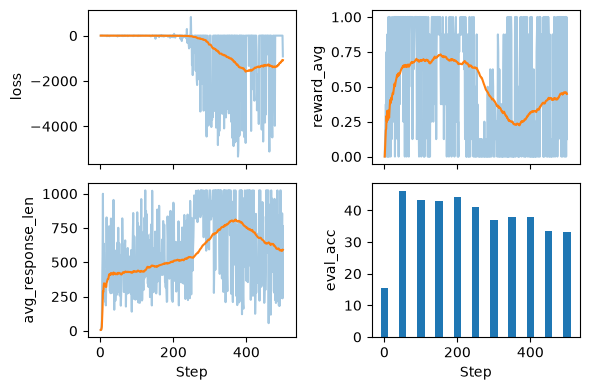

In [5]:
plot_grpo_metrics(
    "ch06_rlvr_grpo_original_no_kl_metrics.csv",
    columns=["loss", "reward_avg", "avg_response_len", "eval_acc"]
)

In [ ]:
# download_from_github(
#     "ch03/02_math500-verifier-scripts/evaluate_math500.py"
# )

# 7.3 Tracking more advanced GRPO performance metrics

In [6]:
import torch

def compute_advantage_stats(rewards_list):

    rewards = torch.tensor(rewards_list)
    advantages = (rewards - rewards.mean()) / (rewards.std() + 1e-4)


    adv_avg = advantages.mean().item()
    adv_std = advantages.std().item()

    return advantages, adv_avg, adv_std

In [7]:
adv, adv_avg, adv_std = compute_advantage_stats([1., 1., 0., 0.])
print(f"Advantages: {adv}")
print(f"Advantage mean = {adv_avg:.4f}, std = {adv_std:.4f}")

Advantages: tensor([ 0.8659,  0.8659, -0.8659, -0.8659])
Advantage mean = 0.0000, std = 0.9998


In [ ]:
logits = torch.tensor([
    0.6667, -2.0000,  1.3333, -0.0000, -0.6667,  2.0000, -1.3333
])
# wersja z dominacja jednej wartosci
# logits = torch.tensor([ 
#     0.6667, -2.0000,  1.3333, -0.0000, -0.6667,  20.0000, -1.3333
# ])

In [12]:
logprobs = torch.log_softmax(logits, dim=-1)
print("All token logprobs:", logprobs)

selected_token = torch.argmax(logprobs)
selected = logprobs[selected_token]
print("Selected token ID:", selected_token)
print("Selected token logprob:", selected)

All token logprobs: tensor([-19.3333, -22.0000, -18.6667, -20.0000, -20.6667,   0.0000, -21.3333])
Selected token ID: tensor(5)
Selected token logprob: tensor(0.)


In [13]:
probs = torch.softmax(logits, dim=-1)
logprobs = torch.log_softmax(logits, dim=-1)
entropy = torch.sum(-(probs * logprobs))

print("Probs:", probs)
print("Entropy:", entropy)

Probs: tensor([4.0147e-09, 2.7895e-10, 7.8191e-09, 2.0612e-09, 1.0582e-09, 1.0000e+00,
        5.4333e-10])
Entropy: tensor(3.0439e-07)


In [14]:
print("Probs:", torch.exp(logprobs))

Probs: tensor([4.0147e-09, 2.7895e-10, 7.8191e-09, 2.0612e-09, 1.0582e-09, 1.0000e+00,
        5.4333e-10])


In [15]:
def sequence_logprob_and_entropy(model, token_ids, prompt_len):

    logits = model(token_ids.unsqueeze(0)).squeeze(0).float()
    logprobs = torch.log_softmax(logits, dim=-1)

    targets = token_ids[1:]
    selected = logprobs[:-1].gather(1, targets.unsqueeze(-1)).squeeze(-1)

    selected_answer_logprobs = selected[prompt_len - 1:]
    logp_all_steps = torch.sum(selected_answer_logprobs)

    all_answer_logprobs = logprobs[:-1][prompt_len - 1:]
    if all_answer_logprobs.numel() == 0:
        entropy_all_steps = logp_all_steps.new_tensor(0.0) 
    else: 
        all_answer_probs = torch.exp(all_answer_logprobs)
        plogp = all_answer_probs * all_answer_logprobs
        step_entropy = -torch.sum(plogp, dim=-1)
        entropy_all_steps = torch.mean(step_entropy)

    return logp_all_steps, entropy_all_steps 

In [ ]:
# długo
# download_from_github(
#     "ch07/03_rlvr_grpo_scripts_advanced/7_3_plus_tracking.py"
# )

7_3_plus_tracking.py: 17.0 KB


7_3_plus_tracking_metrics.csv: 39.0 KB


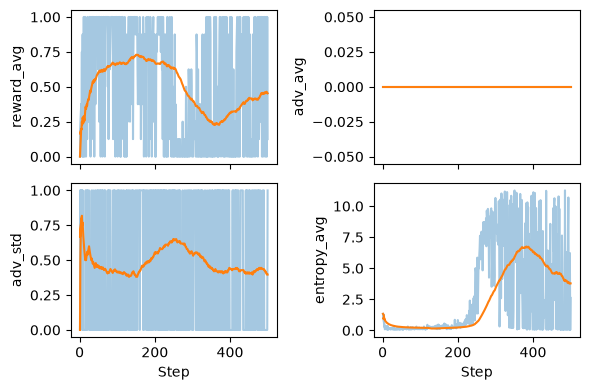

In [17]:
download_from_github(
    "ch07/02_logs/7_3_plus_tracking_metrics.csv"
)
plot_grpo_metrics(
    "7_3_plus_tracking_metrics.csv",
    columns=["reward_avg", "adv_avg", "adv_std", "entropy_avg"]
)